In [4]:
import json
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt


torch.manual_seed(0)
random.seed(0)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: mps


In [6]:
from sklearn.model_selection import train_test_split

images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())

image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)

print(f"Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")


Train: 41470, Val: 5184, Test: 5184


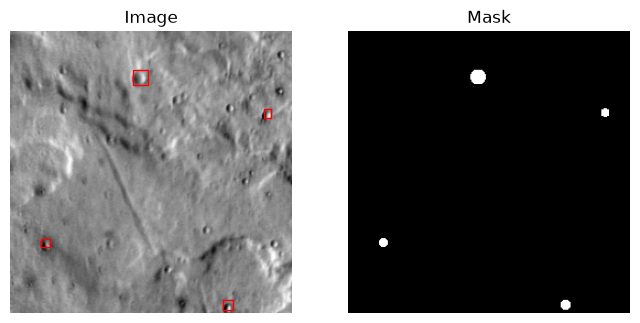

In [13]:
from matplotlib.patches import Rectangle


def make_mask(boxes):
    mask = np.zeros((256, 256), dtype=np.uint8)
    yy, xx = np.mgrid[0:256, 0:256]

    for x, y, w, h in boxes:
        cx = x + w / 2
        cy = y + h / 2
        r = max(w, h) / 2
        inside = (xx + 0.5 - cx) ** 2 + (yy + 0.5 - cy) ** 2 <= r ** 2
        mask[inside] = 1

    return mask


image_id = train_ids[0]
image = plt.imread(images_path / f"{image_id}.png")
mask = make_mask(data[image_id])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.imshow(image, cmap="gray")
for x, y, w, h in data[image_id]:
    ax1.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=1))
ax1.set_title("Image")
ax1.axis("off")

ax2.imshow(mask, cmap="gray")
ax2.set_title("Mask")
ax2.axis("off")

plt.show()

In [14]:
class CraterDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("L")
        image = torch.tensor(np.array(image), dtype=torch.float32) / 255.0
        image = image.unsqueeze(0)

        mask = make_mask(data[image_id])
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask


train_set = CraterDataset(train_ids)
val_set = CraterDataset(val_ids)
test_set = CraterDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader = DataLoader(val_set, batch_size=16, shuffle=False)
test_loader = DataLoader(test_set, batch_size=16, shuffle=False)

images, masks = next(iter(train_loader))
print(images.shape)
print(masks.shape)

torch.Size([16, 1, 256, 256])
torch.Size([16, 1, 256, 256])


In [15]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        # shrinking half
        self.down1 = conv_block(1, 32)      # (32, 256, 256)
        self.down2 = conv_block(32, 64)     # (64, 128, 128)
        self.down3 = conv_block(64, 128)    # (128, 64, 64)
        self.bottom = conv_block(128, 256)  # (256, 32, 32)

        # growing half
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)  # (128, 64, 64)
        self.conv3 = conv_block(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # (64, 128, 128)
        self.conv2 = conv_block(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # (32, 256, 256)
        self.conv1 = conv_block(64, 32)

        self.out = nn.Conv2d(32, 1, kernel_size=1)  # (1, 256, 256)

    def forward(self, x):
        d1 = self.down1(x)
        d2 = self.down2(self.pool(d1))
        d3 = self.down3(self.pool(d2))
        b = self.bottom(self.pool(d3))

        u3 = self.conv3(torch.cat([self.up3(b), d3], dim=1))
        u2 = self.conv2(torch.cat([self.up2(u3), d2], dim=1))
        u1 = self.conv1(torch.cat([self.up1(u2), d1], dim=1))
        return self.out(u1)

model = UNet().to(device)
print(sum(p.numel() for p in model.parameters()))

with torch.no_grad():
    out = model(images.to(device))
print(out.shape)

1925025
torch.Size([16, 1, 256, 256])
